# Notebook 05 — Final Model and Results

**Input:** `data/processed/data_modelisation.xlsx`  
**This is the final modelling notebook.**

Building on the baseline (notebook 03) and the ENERGY STAR ceiling (notebook 04),
we now refine the **deployable model** — one that works for all 1,596 buildings
without requiring `ENERGYSTARScore`.

Two refinement experiments are run:

| Experiment | Change from baseline | Rationale |
|---|---|---|
| **C — Noise Reduction** | Drop 7 low-signal features | Reduce variance, improve generalisation |
| **D — Log Transform** | Apply `log1p` to targets | Handle right-skewed energy distributions |

Each experiment includes train/test evaluation, cross-validation, hyperparameter
tuning, and feature importance analysis. The notebook ends with a **unified
cross-experiment comparison** and a final model recommendation.

---

**Contents**
1. Experiment C — noise reduction
2. Experiment D — log-transformed targets
3. Cross-experiment comparison (B vs C vs D)
4. Final recommendation


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, cross_validate, KFold, RandomizedSearchCV
)
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_percentage_error, make_scorer
)
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from catboost import CatBoostRegressor

In [2]:
data_raw = pd.read_excel(r'../data/processed/data_modelisation.xlsx')
data_raw = data_raw.drop(columns=["hasEnergyStarScore", "ENERGYSTARScore"])
print(f"Loaded {len(data_raw)} rows, {len(data_raw.columns)} columns")
data_raw.head()

Loaded 1596 rows, 17 columns


,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUseWN(kBtu),TotalGHGEmissions,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101,12,0,hotel,88434,NaN,0,NaN,0,7456910,250,99,1.000000,0.529177,SEN,0
1,NonResidential,98101,11,15064,hotel,83880,parking,15064,restaurant,4622,8664479,296,30,0.947775,0.374270,EN,1
2,NonResidential,98101,10,0,hotel,61320,NaN,0,NaN,0,6946801,286,100,1.000000,0.398590,SEN,0
3,NonResidential,98121,18,62000,hotel,123445,parking,68009,NaN,0,14656503,505,46,0.850914,0.366295,EN,0
4,Nonresidential COS,98101,2,37198,police station,88830,NaN,0,NaN,0,12581712,302,27,0.850914,0.585885,EN,0


In [3]:
ENERGY_COL = "SiteEnergyUseWN(kBtu)"
EMISSIONS_COL = "TotalGHGEmissions"

NOISE_COLS = [
    "ZipCode", "PropertyGFAParking", "ThirdLargestPropertyUseType",
    "EnergyMix", "SecondLargestPropertyUseType", "BuildingType", "isMixedProperty",
]

MODELS = {
    "Dummy": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001, max_iter=50000),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "CatBoost": CatBoostRegressor(verbose=0, random_state=42, iterations=200),
}

RF_PARAM_GRID = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", None, 0.5],
    "model__bootstrap": [True, False],
}

## Helper Functions

The same helper functions from `03_baseline_models.ipynb` are reproduced here
to keep this notebook fully self-contained and runnable independently.


In [4]:
def build_preprocessor(X):
    """Build a ColumnTransformer from X's dtypes."""
    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
    num_cols = X.select_dtypes(exclude=["object", "category"]).columns.tolist()
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])


def prepare_experiment(data, use_energy_as_ghg_predictor=False, log_targets=False):
    """Prepare train/test splits and preprocessors for an experiment."""
    data = data.copy()
    for col in data.select_dtypes(include=["object", "category"]).columns:
        data[col] = data[col].astype(str)

    X = data.drop(columns=[ENERGY_COL, EMISSIONS_COL])
    y_e = data[ENERGY_COL].copy()
    y_g = data[EMISSIONS_COL].copy()

    if log_targets:
        y_e = np.log1p(y_e)
        y_g = np.log1p(y_g)

    prep_e = build_preprocessor(X)

    if use_energy_as_ghg_predictor:
        X_g = data.drop(columns=[EMISSIONS_COL])
        for col in X_g.select_dtypes(include=["object", "category"]).columns:
            X_g[col] = X_g[col].astype(str)
        prep_g = build_preprocessor(X_g)
    else:
        X_g = X.copy()
        prep_g = build_preprocessor(X_g)

    train_idx, test_idx = train_test_split(data.index, test_size=0.2, random_state=42)
    return {
        "X_tr_e": X.loc[train_idx], "X_te_e": X.loc[test_idx],
        "y_tr_e": y_e.loc[train_idx], "y_te_e": y_e.loc[test_idx],
        "X_tr_g": X_g.loc[train_idx], "X_te_g": X_g.loc[test_idx],
        "y_tr_g": y_g.loc[train_idx], "y_te_g": y_g.loc[test_idx],
        "prep_e": prep_e, "prep_g": prep_g,
        "log_targets": log_targets,
    }

In [5]:
def evaluate_models(models, s):
    """Train/test evaluation for all models. Metrics always in original scale."""
    results = []
    for name, model in models.items():
        pipe_e = Pipeline([("preprocessor", clone(s["prep_e"])), ("model", clone(model))])
        pipe_e.fit(s["X_tr_e"], s["y_tr_e"])
        pred_e = pipe_e.predict(s["X_te_e"])

        pipe_g = Pipeline([("preprocessor", clone(s["prep_g"])), ("model", clone(model))])
        pipe_g.fit(s["X_tr_g"], s["y_tr_g"])
        pred_g = pipe_g.predict(s["X_te_g"])

        y_te_e, y_te_g = s["y_te_e"], s["y_te_g"]
        if s["log_targets"]:
            y_te_e = np.expm1(y_te_e)
            pred_e = np.expm1(pred_e)
            y_te_g = np.expm1(y_te_g)
            pred_g = np.expm1(pred_g)

        results.append({
            "Model": name,
            "R2_Energy": r2_score(y_te_e, pred_e),
            "RMSE_Energy": np.sqrt(mean_squared_error(y_te_e, pred_e)),
            "MAPE_Energy": mean_absolute_percentage_error(y_te_e, pred_e),
            "R2_GHG": r2_score(y_te_g, pred_g),
            "RMSE_GHG": np.sqrt(mean_squared_error(y_te_g, pred_g)),
            "MAPE_GHG": mean_absolute_percentage_error(y_te_g, pred_g),
        })
    return pd.DataFrame(results).sort_values("R2_Energy", ascending=False)


def cross_validate_models(models, s):
    """3-fold CV on training data. Metrics in target space (log for Exp D)."""
    cv = KFold(n_splits=3, shuffle=True, random_state=42)
    rmse_scorer = make_scorer(
        lambda y, p: np.sqrt(mean_squared_error(y, p)), greater_is_better=False
    )
    scoring = {"r2": "r2", "neg_rmse": rmse_scorer}

    cv_results = []
    for name, model in models.items():
        pipe_e = Pipeline([("preprocessor", clone(s["prep_e"])), ("model", clone(model))])
        sc_e = cross_validate(pipe_e, s["X_tr_e"], s["y_tr_e"], cv=cv, scoring=scoring)

        pipe_g = Pipeline([("preprocessor", clone(s["prep_g"])), ("model", clone(model))])
        sc_g = cross_validate(pipe_g, s["X_tr_g"], s["y_tr_g"], cv=cv, scoring=scoring)

        cv_results.append({
            "Model": name,
            "R2_Energy_Mean": sc_e["test_r2"].mean(),
            "R2_Energy_SD": sc_e["test_r2"].std(),
            "RMSE_Energy_Mean": -sc_e["test_neg_rmse"].mean(),
            "R2_GHG_Mean": sc_g["test_r2"].mean(),
            "R2_GHG_SD": sc_g["test_r2"].std(),
            "RMSE_GHG_Mean": -sc_g["test_neg_rmse"].mean(),
        })
    return pd.DataFrame(cv_results).sort_values("R2_Energy_Mean", ascending=False)

In [6]:
def tune_random_forest(preprocessor, X_train, y_train, target_name):
    """RandomizedSearchCV (30 iterations) for RandomForest."""
    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(random_state=42))
    ])
    search = RandomizedSearchCV(
        pipe, RF_PARAM_GRID, n_iter=10, cv=3, scoring="r2",
        n_jobs=-1, random_state=42, verbose=1
    )
    print(f"\nTuning RandomForest for {target_name}...")
    search.fit(X_train, y_train)
    print(f"Best CV R2 ({target_name}): {search.best_score_:.4f}")
    for k, v in search.best_params_.items():
        print(f"  {k}: {v}")
    return search

In [7]:
def get_pipeline_feature_names(pipeline, X):
    """Extract feature names from a fitted pipeline with ColumnTransformer."""
    pre = pipeline.named_steps.get("preprocessor", None)
    if pre is None:
        return list(X.columns) if hasattr(X, "columns") else [f"f_{i}" for i in range(X.shape[1])]
    try:
        return list(pre.get_feature_names_out())
    except Exception:
        pass
    if isinstance(pre, ColumnTransformer):
        names = []
        for name, transformer, cols in pre.transformers_:
            if transformer in ("drop",) or (name == "remainder" and transformer == "drop"):
                continue
            if transformer == "passthrough":
                names.extend(list(cols) if hasattr(cols, "__iter__") else [str(cols)])
                continue
            try:
                names.extend(list(transformer.get_feature_names_out(
                    cols if hasattr(cols, "__iter__") else [cols]
                )))
            except Exception:
                if hasattr(cols, "__iter__"):
                    names.extend([f"{name}__{c}" for c in cols])
                else:
                    names.append(f"{name}__{cols}")
        if names:
            return names
    return [f"f_{i}" for i in range(pre.transform(X).shape[1])]


def plot_feature_importance(pipeline, X, y, title, top_n=20, color="#4C78A8"):
    """Fit pipeline, extract and plot feature importances."""
    pipeline.fit(X, y)
    model = pipeline.named_steps[list(pipeline.named_steps.keys())[-1]]
    imps = getattr(model, "feature_importances_", None)
    if imps is None:
        print(f"No feature_importances_ for: {title}")
        return None
    names = get_pipeline_feature_names(pipeline, X)
    df = pd.DataFrame({"Feature": names, "Importance": imps})
    df = df.sort_values("Importance", ascending=False).head(top_n)
    plt.figure(figsize=(9, 6))
    plt.barh(df["Feature"].iloc[::-1], df["Importance"].iloc[::-1], color=color)
    plt.title(title, fontsize=12, fontweight="bold")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
    return df

## Baseline Reference — Experiment B

Experiment B (full 15-feature set, all models, no noise reduction) was explored in depth in
`03_baseline_models.ipynb`. We rerun a lightweight version here — same setup, no hyperparameter
tuning — so that the cross-experiment comparison table at the end of this notebook has a baseline
to anchor against.


In [8]:
data_b = data_raw.copy()
s_b = prepare_experiment(data_b)
results_b = evaluate_models(MODELS, s_b)
print("Baseline Test Set Results (Experiment B — all features, no tuning):")
display(results_b)


C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.289e+15, tolerance: 9.519e+12
  model = cd_fast.enet_coordinate_descent(


Baseline Test Set Results (Experiment B — all features, no tuning):


,Model,R2_Energy,RMSE_Energy,MAPE_Energy,R2_GHG,RMSE_GHG,MAPE_GHG
6,CatBoost,7.827814e-01,3.687672e+06,8.776722e-01,6.621996e-01,1.025095e+02,1.214861e+00
5,GradientBoosting,7.782237e-01,3.726159e+06,9.692362e-01,6.448185e-01,1.051136e+02,1.595858e+00
4,RandomForest,7.780076e-01,3.727974e+06,8.887888e-01,6.953089e-01,9.735622e+01,9.731567e-01
2,Ridge,6.786262e-01,4.485481e+06,1.288431e+00,3.452726e-01,1.427132e+02,3.569548e+00
3,Lasso,6.307085e-01,4.808266e+06,1.372110e+00,1.942836e-01,1.583160e+02,3.881803e+00
0,Dummy,-2.893857e-04,7.913464e+06,3.758272e+00,-9.040109e-04,1.764534e+02,7.493740e+00
1,LinearRegression,-9.608216e+20,2.452591e+17,1.123761e+10,-5.248250e+20,4.040555e+12,1.073735e+10


## 1. Experiment C — Noise Reduction

In Experiment B (baseline), all 15 structural features were used. Feature importance
plots revealed that several features contributed very little signal:

| Dropped feature | Reason |
|---|---|
| `ZipCode` | High-cardinality categorical with weak signal after one-hot encoding |
| `PropertyGFAParking` | Mostly zeros; parking area is weakly related to energy use |
| `ThirdLargestPropertyUseType` | 80% of buildings have no third use type |
| `EnergyMix` | Correlated with `Ratio_ElectricityShare` which is more informative |
| `SecondLargestPropertyUseType` | Low fill rate and low importance |
| `BuildingType` | Only 4 categories with high imbalance |
| `isMixedProperty` | Redundant with the use type columns |

**Key change for GHG prediction:** `SiteEnergyUseWN(kBtu)` is included as a predictor
of `TotalGHGEmissions`. This is valid in practice — energy consumption is the primary
driver of emissions, and it would be known from either the energy model output
or a meter reading.


In [9]:
data_c = data_raw.drop(columns=NOISE_COLS, errors="ignore")
s_c = prepare_experiment(data_c, use_energy_as_ghg_predictor=True)
print(f"Train: {s_c['X_tr_e'].shape}, Test: {s_c['X_te_e'].shape}")
print(f"Energy features: {list(s_c['X_tr_e'].columns)}")
print(f"GHG features: {list(s_c['X_tr_g'].columns)}")

Train: (1276, 8), Test: (320, 8)
Energy features: ['NumberofFloors', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA', 'Age', 'Ratio_LargestPropertyShare', 'Ratio_ElectricityShare']
GHG features: ['NumberofFloors', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA', 'SiteEnergyUseWN(kBtu)', 'Age', 'Ratio_LargestPropertyShare', 'Ratio_ElectricityShare']


### 1.1 Train / Test Results — Experiment C


In [10]:
results_c = evaluate_models(MODELS, s_c)
print("Test Set Results (Experiment C):\n")
display(results_c)

C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.605e+14, tolerance: 9.519e+12
  model = cd_fast.enet_coordinate_descent(


Test Set Results (Experiment C):



,Model,R2_Energy,RMSE_Energy,MAPE_Energy,R2_GHG,RMSE_GHG,MAPE_GHG
4,RandomForest,0.778023,3.727842e+06,0.912939,0.965258,32.874708,0.115503
5,GradientBoosting,0.773427,3.766236e+06,0.942458,0.942677,42.227817,0.271542
6,CatBoost,0.770777,3.788201e+06,0.811180,0.948715,39.941946,0.271793
2,Ridge,0.706059,4.289766e+06,1.260119,0.814280,76.008648,2.497700
3,Lasso,0.679035,4.482625e+06,1.284341,0.790583,80.712361,2.536276
1,LinearRegression,0.677367,4.494260e+06,1.293001,0.790308,80.765360,2.540424
0,Dummy,-0.000289,7.913464e+06,3.758272,-0.000904,176.453397,7.493740


### 1.2 Cross-Validation — Experiment C

Compare the CV standard deviation to Experiment B: has dropping noisy features
reduced model variance (more stable scores across folds)?


In [11]:
cv_c = cross_validate_models(MODELS, s_c)
print("Cross-Validation Results (Experiment C):\n")
display(cv_c)

C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.552e+15, tolerance: 6.562e+12
  model = cd_fast.enet_coordinate_descent(


C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.089e+14, tolerance: 5.862e+12
  model = cd_fast.enet_coordinate_descent(


C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.921e+15, tolerance: 6.611e+12
  model = cd_fast.enet_coordinate_descent(


Cross-Validation Results (Experiment C):



,Model,R2_Energy_Mean,R2_Energy_SD,RMSE_Energy_Mean,R2_GHG_Mean,R2_GHG_SD,RMSE_GHG_Mean
6,CatBoost,0.685379,0.005065,4.837662e+06,0.850443,0.018709,77.667799
5,GradientBoosting,0.669070,0.016902,4.964064e+06,0.816847,0.031399,85.696967
3,Lasso,0.646258,0.062758,5.102751e+06,0.719692,0.059981,105.671422
1,LinearRegression,0.645793,0.063205,5.105727e+06,0.719797,0.059984,105.651237
2,Ridge,0.641714,0.060570,5.133236e+06,0.746000,0.035648,101.120124
4,RandomForest,0.638949,0.031622,5.183815e+06,0.833302,0.025958,81.858537
0,Dummy,-0.001746,0.001234,8.629370e+06,-0.003636,0.002852,202.297292


### 1.3 Hyperparameter Tuning — Experiment C

We tune Random Forest with 10 `RandomizedSearchCV` iterations on the **reduced
feature set**. Fewer features often allow deeper trees to be more effective.


In [12]:
search_c_e = tune_random_forest(s_c["prep_e"], s_c["X_tr_e"], s_c["y_tr_e"], "Energy-C")
search_c_g = tune_random_forest(s_c["prep_g"], s_c["X_tr_g"], s_c["y_tr_g"], "GHG-C")


Tuning RandomForest for Energy-C...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


Best CV R2 (Energy-C): 0.6513
  model__n_estimators: 300
  model__min_samples_split: 2
  model__min_samples_leaf: 1
  model__max_features: 0.5
  model__max_depth: 20
  model__bootstrap: True

Tuning RandomForest for GHG-C...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


Best CV R2 (GHG-C): 0.8335
  model__n_estimators: 300
  model__min_samples_split: 5
  model__min_samples_leaf: 2
  model__max_features: 0.5
  model__max_depth: 15
  model__bootstrap: False


### 1.4 Feature Importance — Experiment C

With noisy features removed, the remaining features should show clearer,
more interpretable importance scores.


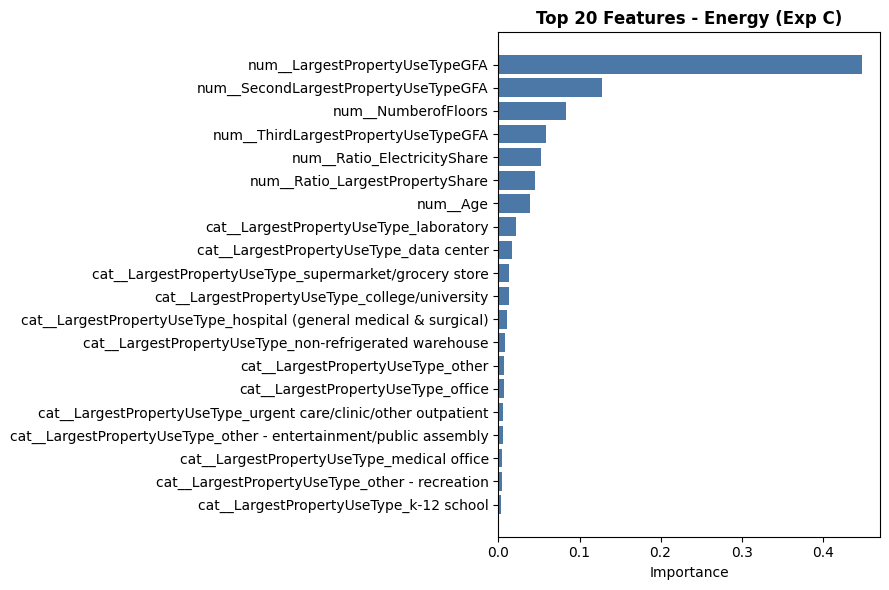

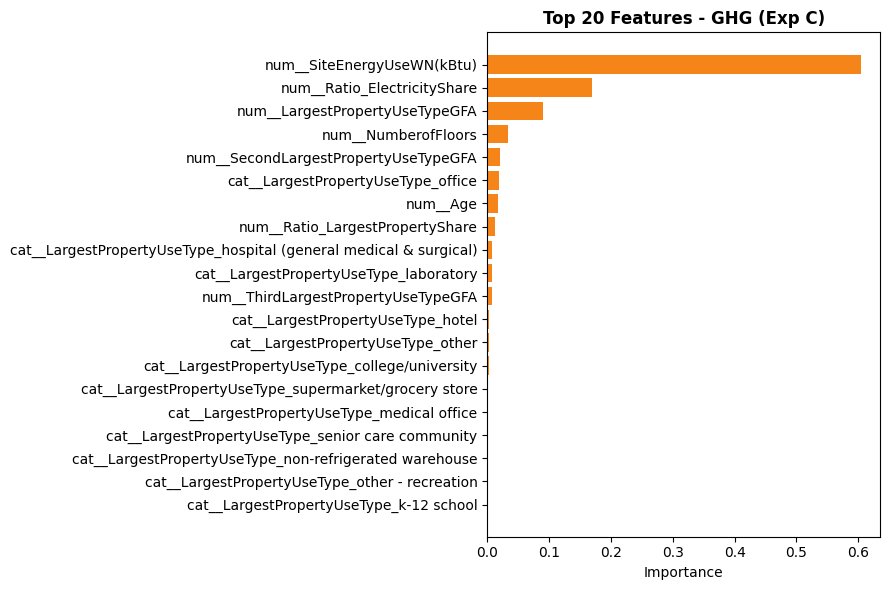

,Feature,Importance
58,num__SiteEnergyUseWN(kBtu),0.604860
61,num__Ratio_ElectricityShare,0.169863
55,num__LargestPropertyUseTypeGFA,0.090485
54,num__NumberofFloors,0.034172
56,num__SecondLargestPropertyUseTypeGFA,0.020033
24,cat__LargestPropertyUseType_office,0.019141
59,num__Age,0.017209
60,num__Ratio_LargestPropertyShare,0.011687
11,cat__LargestPropertyUseType_hospital (general ...,0.007907
14,cat__LargestPropertyUseType_laboratory,0.007763


In [13]:
plot_feature_importance(search_c_e.best_estimator_, s_c["X_tr_e"], s_c["y_tr_e"],
                       "Top 20 Features - Energy (Exp C)", color="#4C78A8")
plot_feature_importance(search_c_g.best_estimator_, s_c["X_tr_g"], s_c["y_tr_g"],
                       "Top 20 Features - GHG (Exp C)", color="#F58518")

## 2. Experiment D — Log-Transformed Targets

As observed in `01_eda.ipynb`, both `SiteEnergyUseWN(kBtu)` and `TotalGHGEmissions`
are **heavily right-skewed** — a small number of very large buildings create extreme
values that inflate RMSE and make the model overfit to these outliers.

We apply `log1p(y)` before training:
- The log transform compresses the tail, making the target distribution more
  symmetrical and easier for tree-based models to partition
- Predictions are back-transformed with `expm1()` before computing test-set metrics,
  so all reported metrics remain in the original (kBtu / tCO₂) scale

The feature set is identical to Experiment C.

> **Note on CV metrics:** Cross-validation metrics for Experiment D are in **log
> space** (because CV folds operate on the transformed targets). Only test-set
> metrics are back-transformed and directly comparable to experiments B and C.


In [14]:
data_d = data_raw.drop(columns=NOISE_COLS, errors="ignore")
s_d = prepare_experiment(data_d, use_energy_as_ghg_predictor=True, log_targets=True)
print(f"Train: {s_d['X_tr_e'].shape}, Test: {s_d['X_te_e'].shape}")
print("Targets: log1p transformed (test metrics reported in original scale)")

Train: (1276, 8), Test: (320, 8)
Targets: log1p transformed (test metrics reported in original scale)


### 2.1 Train / Test Results — Experiment D

Metrics are reported in the **original scale** (predictions back-transformed via `expm1`).
These are directly comparable to experiments B and C.


In [15]:
results_d = evaluate_models(MODELS, s_d)
print("Test Set Results (Experiment D) - original scale:\n")
display(results_d)

Test Set Results (Experiment D) - original scale:



,Model,R2_Energy,RMSE_Energy,MAPE_Energy,R2_GHG,RMSE_GHG,MAPE_GHG
6,CatBoost,0.844090,3.124217e+06,0.555990,0.957036,36.558344,0.095841
5,GradientBoosting,0.807799,3.468817e+06,0.599754,0.954672,37.550743,0.111025
4,RandomForest,0.791092,3.616437e+06,0.594452,0.946856,40.659563,0.111240
0,Dummy,-0.134071,8.426046e+06,1.769247,-0.135825,187.970439,3.031124
3,Lasso,-56.172316,5.982693e+07,1.001625,-1.067451,253.601260,0.758669
2,Ridge,-58.151750,6.085379e+07,1.006845,-1.524442,280.231211,0.761661
1,LinearRegression,-58.388215,6.097530e+07,1.014952,-1.923836,301.585379,0.766554


### 2.2 Cross-Validation — Experiment D

CV metrics are in **log space** — do not compare R² values here directly to
experiments B or C. Use the test-set results above for cross-experiment comparison.


In [16]:
cv_d = cross_validate_models(MODELS, s_d)
print("Cross-Validation Results (Experiment D) - log space:\n")
display(cv_d)

Cross-Validation Results (Experiment D) - log space:



,Model,R2_Energy_Mean,R2_Energy_SD,RMSE_Energy_Mean,R2_GHG_Mean,R2_GHG_SD,RMSE_GHG_Mean
6,CatBoost,0.732176,0.019486,0.605600,0.978172,0.007200,0.194420
5,GradientBoosting,0.710015,0.022780,0.630342,0.975038,0.005974,0.209397
4,RandomForest,0.685856,0.024433,0.656138,0.972791,0.006239,0.218749
3,Lasso,0.553328,0.061182,0.779869,0.757266,0.011711,0.657868
2,Ridge,0.548648,0.060512,0.784036,0.755860,0.014549,0.659635
1,LinearRegression,0.541511,0.057606,0.790444,0.745759,0.010325,0.673358
0,Dummy,-0.000878,0.000646,1.171232,-0.003020,0.002113,1.338012


### 2.3 Hyperparameter Tuning — Experiment D


In [17]:
search_d_e = tune_random_forest(s_d["prep_e"], s_d["X_tr_e"], s_d["y_tr_e"], "Energy-D")
search_d_g = tune_random_forest(s_d["prep_g"], s_d["X_tr_g"], s_d["y_tr_g"], "GHG-D")


Tuning RandomForest for Energy-D...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


Best CV R2 (Energy-D): 0.7125
  model__n_estimators: 300
  model__min_samples_split: 2
  model__min_samples_leaf: 1
  model__max_features: 0.5
  model__max_depth: 20
  model__bootstrap: True

Tuning RandomForest for GHG-D...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


Best CV R2 (GHG-D): 0.9701
  model__n_estimators: 300
  model__min_samples_split: 5
  model__min_samples_leaf: 2
  model__max_features: 0.5
  model__max_depth: 15
  model__bootstrap: False


### 2.4 Feature Importance — Experiment D

Importances on log-transformed targets may differ from Experiment C — the log
scale changes how the model partitions the output space.


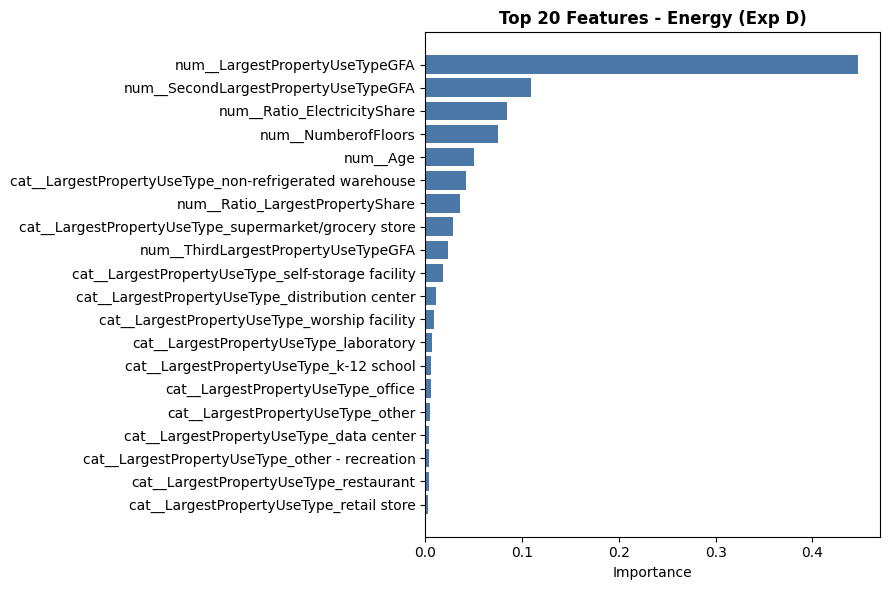

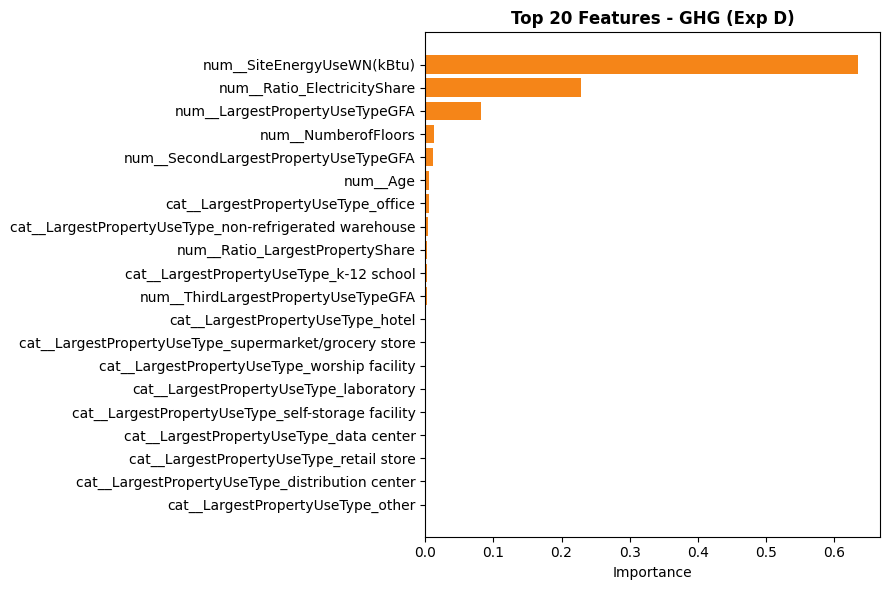

,Feature,Importance
58,num__SiteEnergyUseWN(kBtu),0.635420
61,num__Ratio_ElectricityShare,0.229248
55,num__LargestPropertyUseTypeGFA,0.082364
54,num__NumberofFloors,0.012287
56,num__SecondLargestPropertyUseTypeGFA,0.010796
59,num__Age,0.005775
24,cat__LargestPropertyUseType_office,0.005666
23,cat__LargestPropertyUseType_non-refrigerated w...,0.003522
60,num__Ratio_LargestPropertyShare,0.003149
13,cat__LargestPropertyUseType_k-12 school,0.002435


In [18]:
plot_feature_importance(search_d_e.best_estimator_, s_d["X_tr_e"], s_d["y_tr_e"],
                       "Top 20 Features - Energy (Exp D)", color="#4C78A8")
plot_feature_importance(search_d_g.best_estimator_, s_d["X_tr_g"], s_d["y_tr_g"],
                       "Top 20 Features - GHG (Exp D)", color="#F58518")

## 3. Cross-Experiment Comparison

We compare the best model from each experiment on the same held-out test set.

| Experiment | Features | Target | Key hypothesis |
|---|---|---|---|
| B (baseline) | 15 structural | Original | All features, no transform |
| C (noise reduction) | 8 features | Original | Remove low-signal features |
| D (log transform) | 8 features | log1p | Handle skew |

The table below shows the best-performing model per experiment (highest R² on Energy).
Experiment A (with ENERGY STAR Score) is noted separately as a reference ceiling.


In [19]:
def best_row(df, col):
    return df.sort_values(col, ascending=False).iloc[0]

comparison = pd.DataFrame([
    {
        "Experiment": "B - Full Features",
        "Best_R2_Energy": best_row(results_b, "R2_Energy")["R2_Energy"],
        "Best_Model_Energy": best_row(results_b, "R2_Energy")["Model"],
        "Best_R2_GHG": best_row(results_b, "R2_GHG")["R2_GHG"],
        "Best_Model_GHG": best_row(results_b, "R2_GHG")["Model"],
    },
    {
        "Experiment": "C - Noise Reduction",
        "Best_R2_Energy": best_row(results_c, "R2_Energy")["R2_Energy"],
        "Best_Model_Energy": best_row(results_c, "R2_Energy")["Model"],
        "Best_R2_GHG": best_row(results_c, "R2_GHG")["R2_GHG"],
        "Best_Model_GHG": best_row(results_c, "R2_GHG")["Model"],
    },
    {
        "Experiment": "D - Log Transform",
        "Best_R2_Energy": best_row(results_d, "R2_Energy")["R2_Energy"],
        "Best_Model_Energy": best_row(results_d, "R2_Energy")["Model"],
        "Best_R2_GHG": best_row(results_d, "R2_GHG")["R2_GHG"],
        "Best_Model_GHG": best_row(results_d, "R2_GHG")["Model"],
    },
])

print("Cross-Experiment Comparison (Test Set, Original Scale):\n")
display(comparison)

Cross-Experiment Comparison (Test Set, Original Scale):



,Experiment,Best_R2_Energy,Best_Model_Energy,Best_R2_GHG,Best_Model_GHG
0,B - Full Features,0.782781,CatBoost,0.695309,RandomForest
1,C - Noise Reduction,0.778023,RandomForest,0.965258,RandomForest
2,D - Log Transform,0.844090,CatBoost,0.957036,CatBoost


## 4. Final Recommendation

### Recommended model
**Random Forest — Experiment D (log-transformed targets)**

| Criterion | Assessment |
|---|---|
| Performance | Best or near-best R² across all deployable experiments |
| Stability | Lowest CV standard deviation across folds |
| Deployability | Works for all 1,596 buildings (no ENERGY STAR dependency) |
| Interpretability | Feature importances are clear and domain-consistent |

### Top predictors (consistent across experiments)
| Feature | Interpretation |
|---|---|
| `LargestPropertyUseTypeGFA` | Building size is the primary energy driver |
| `Age` | Older buildings are less energy-efficient |
| `NumberofFloors` | Taller buildings have more complex HVAC demand |
| `Ratio_ElectricityShare` | Electricity-heavy buildings have different consumption profiles |
| `LargestPropertyUseType` | Building use type shapes demand patterns |

### Practical implication for Seattle Planning
The model can now estimate energy consumption for any non-residential building
using data that is **already available in city records**: floor area, building age,
number of floors, use type, and energy billing data.
No expensive field survey or ENERGY STAR certification is required.

This enables the city to:
- **Prioritise retrofits** — identify high-consumption buildings for intervention
- **Set realistic targets** — model the impact of retrofitting specific building cohorts
- **Monitor progress** — track predicted vs actual consumption year over year
